# Check data

In [26]:
import pandas as pd
df = pd.read_pickle('../data/adsorption/df_all_fixed.pkl')
df = df.query("system_subtype == 'Mixture 5'")
df = df.drop(columns=['system', 'system_subtype', 'alkene'])
df.head()

,mol_uc_avg,n,temperature,adsorption_type,pressure
0,-17.854477,10,300,excess,1080000.0
1,0.003240,10,300,absolute,1080000.0
2,-17.797652,8,300,excess,1080000.0
3,1.168620,6,300,absolute,1080000.0
4,3.157465,4,300,excess,1080000.0


In [27]:
df.groupby('n').size().reset_index(name='count')

,n,count
0,2,242
1,4,242
2,6,242
3,8,242
4,10,242


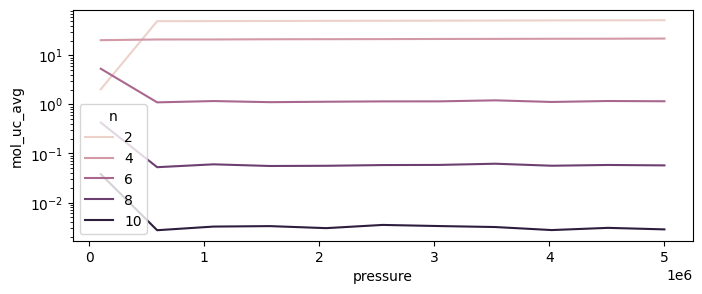

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

sns.lineplot(
    data=df.query('temperature == 300 and adsorption_type=="absolute"'),
    x='pressure',
    y='mol_uc_avg', hue='n')
ax.set_yscale('log')

In [ ]:
df.to_csv('../data/processed/adsorption_mixture_5.csv', index=False)

# Make ml model

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/processed/adsorption_mixture_5.csv')
data.head()

data['log_mol_uc_avg'] = data['mol_uc_avg'].apply(lambda x: -np.log10(np.abs(x)) if x < 0 else np.log10(x))
data['pressure_bar'] = data['pressure'] / 1e5
data['adsorption_type_num'] = data['adsorption_type'].map({'absolute': 0, 'excess': 1})
# data = data[data.adsorption_type_num == 0]

## LightGBM (does not work)

In [66]:
import numpy as np
import lightgbm as lgb
from lightgbm.callback import early_stopping, log_evaluation, record_evaluation
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_log_error, mean_squared_error

# 1) Features & target
X = data[['pressure_bar', 'temperature', 'n', 'adsorption_type_num']]
y = data['mol_uc_avg']

# 2) Define your custom metrics
def rmsle_eval(preds, dataset):
    labels = dataset.get_label()
    preds  = np.maximum(preds, 0)
    return 'rmsle', np.sqrt(mean_squared_log_error(labels, preds)), False

def rmse_eval(preds, dataset):
    labels = dataset.get_label()
    preds  = np.maximum(preds, 0)
    return 'rmse', np.sqrt(mean_squared_error(labels, preds)), False

# 3) LightGBM params (same for every fold)
params = {
    'objective': 'regression',
    'metric': 'None',
    'num_leaves': 31,
    'learning_rate': 0.02,
    'feature_fraction': 0.9,
}

# 4) Prepare 10-fold splitter
kf = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_scores  = []
rmsle_scores = []

models = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), 1):
    print(f"\n=== Fold {fold} ===")
    X_tr, X_val = X.iloc[train_idx], X.iloc[valid_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[valid_idx]

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dvalid = lgb.Dataset(X_val, label=y_val, reference=dtrain)

    # 5) Train with early stopping & logging
    evals_result = {}
    model = lgb.train(
        params,
        dtrain,
        num_boost_round=1000,
        valid_sets=[dtrain, dvalid],
        valid_names=['train','valid'],
        feval=rmsle_eval,
        callbacks=[
            early_stopping(stopping_rounds=50),
            log_evaluation(period=100),
            record_evaluation(evals_result),
        ]
    )
    models.append(model)
    # 6) Predict & score
    y_pred = model.predict(X_val, num_iteration=model.best_iteration)
    rmse  = mean_squared_error(y_val, y_pred)
    rmsle = np.sqrt(mean_squared_log_error(y_val, np.where(y_pred < 0, 0, y_pred)))

    print(f" Fold {fold} — best_iter={model.best_iteration}:  RMSE={rmse:.4f},  RMSLE={rmsle:.4f}")
    
    rmse_scores .append(rmse)
    rmsle_scores.append(rmsle)




=== Fold 1 ===
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004998 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 30
[LightGBM] [Info] Number of data points in the train set: 544, number of used features: 3
[LightGBM] [Info] Start training from score 6.707191
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

## Knn (works)

In [4]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib

class AdsorptionKNN(BaseEstimator):
    """
    A grouped KNN regressor for adsorption data that scales inputs and
    maintains one KNN per combination of `n` and `adsorption_type_num`.
    Supports serialization via joblib.dump and loading via joblib.load.
    """
    def __init__(self, n_neighbors=2, weights='distance', metric='euclidean'):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.metric = metric
        self.scaler = StandardScaler()
        # keys will be tuples of (n, adsorption_type_num)
        self.knn_models = {}

    def fit(self, data: pd.DataFrame, y_col: str = 'mol_uc_avg'):
        """
        Fit the scaler on ['pressure_bar','temperature'] and build a KNN per group.
        data must include columns ['pressure_bar','temperature','n','adsorption_type_num', y_col].
        """
        # Fit global scaler
        features = data[['pressure_bar', 'temperature']].values
        self.scaler.fit(features)

        # Group by both n and adsorption_type_num
        groups = data.groupby(['n', 'adsorption_type_num'])
        for (n_val, ads_type), group in groups:
            X_grp = group[['pressure_bar', 'temperature']].values
            y_grp = group[y_col].values
            X_scaled = self.scaler.transform(X_grp)

            knn = KNeighborsRegressor(
                n_neighbors=self.n_neighbors,
                weights=self.weights,
                metric=self.metric
            )
            knn.fit(X_scaled, y_grp)
            self.knn_models[(n_val, ads_type)] = knn
        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        """
        Predict adsorption values for df with columns ['pressure_bar','temperature','n','adsorption_type_num'].
        Returns array of predictions or np.nan for unseen (n,adsorption_type_num) pairs.
        """
        preds = []
        for _, row in df.iterrows():
            key = (row['n'], row['adsorption_type_num'])
            model = self.knn_models.get(key)
            if model is None:
                preds.append(np.nan)
            else:
                pt = np.array([[row['pressure_bar'], row['temperature']]])
                pt_scaled = self.scaler.transform(pt)
                preds.append(model.predict(pt_scaled)[0])
        return np.array(preds)

    # Allow loaded model to be called directly
    __call__ = predict

# Example usage:
# 1) Fit and save model
ads_model = AdsorptionKNN(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_model.pkl')

# 2) Later, load and predict
# ads_model_loaded = joblib.load('knn_adsorption_model.pkl')
# X_test = pd.DataFrame({
#     'pressure_bar': [1.0, 5.2, 3.3],
#     'temperature':  [300, 310, 295],
#     'n':            [2,   4,   2]
# })
# y_pred = ads_model_loaded(X_test)
# print(y_pred)

['../data/processed/knn_adsorption_model.pkl']

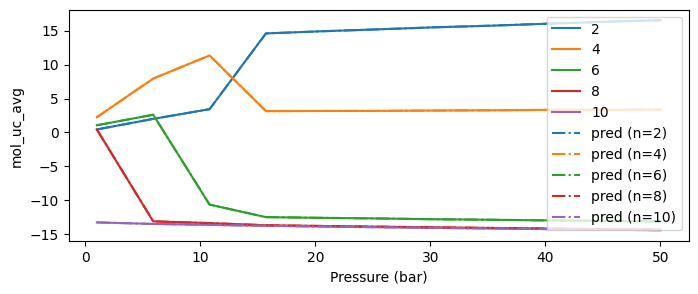

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)
temperature = 420

# define a 5-color mapping for n=2,4,6,8,10
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# plot the existing data with that same palette
sns.lineplot(
    data=data.query(
        'temperature == @temperature and adsorption_type=="excess"'
    ),
    x='pressure_bar', y='mol_uc_avg',
    hue='n', palette=palette,
    ax=ax
)

m = 51
pressure = np.linspace(1, 50, m)
for n_val in range(2, 11, 2):
    X_test = pd.DataFrame({
        'pressure_bar': pressure,
        'temperature': [temperature] * m,
        'n':           [n_val] * m,
        'adsorption_type_num': [1] * m
    })
    y_pred = ads_model_loaded(X_test)
    ax.plot(
        pressure, y_pred,
        color=palette[n_val],       # same color as the data line
        linestyle='-.',              # dash-dot only for preds
        label=f'pred (n={n_val})'
    )

# ax.set_yscale('log')
ax.set_xlabel('Pressure (bar)')
ax.legend()

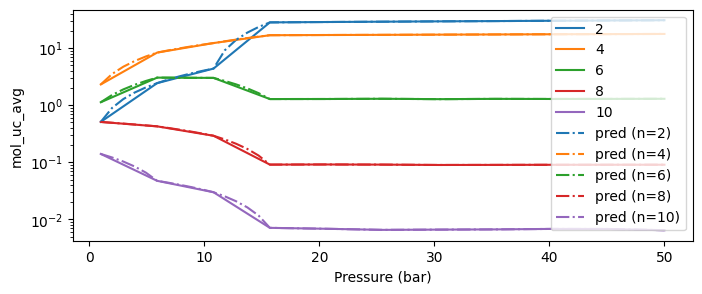

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)
temperature = 420

# define a 5-color mapping for n=2,4,6,8,10
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# plot the existing data with that same palette
sns.lineplot(
    data=data.query(
        'temperature == @temperature and adsorption_type=="absolute"'
    ),
    x='pressure_bar', y='mol_uc_avg',
    hue='n', palette=palette,
    ax=ax
)

m = 51
pressure = np.linspace(1, 50, m)
for n_val in range(2, 11, 2):
    X_test = pd.DataFrame({
        'pressure_bar': pressure,
        'temperature': [temperature] * m,
        'n':           [n_val] * m,
        'adsorption_type_num': [0] * m
    })
    y_pred = ads_model_loaded(X_test)
    ax.plot(
        pressure, y_pred,
        color=palette[n_val],       # same color as the data line
        linestyle='-.',              # dash-dot only for preds
        label=f'pred (n={n_val})'
    )

ax.set_yscale('log')
ax.set_xlabel('Pressure (bar)')
ax.legend()